Dataset shape: (15090, 29)
Date range: 2025-01-31 to 2026-06-17
X shape: (15090, 23)
y shape: (15090,)
Number of predictors: 23
target_risk
Low       3408
Medium    6257
High      5425
Name: count, dtype: int64
\nTraining rows: 11850
Testing rows: 3030
Training period: 2025-01-31 to 2026-03-01
Testing period: 2026-03-09 to 2026-06-17
\nTraining classes:\n target_risk
Low       2733
Medium    4794
High      4323
Name: count, dtype: int64
\nTesting classes:\n target_risk
Low        622
Medium    1371
High      1037
Name: count, dtype: int64
Fold 1: 7140 train rows, 900 validation rows; validation 2025-10-03 to 2025-11-01
Fold 2: 8040 train rows, 900 validation rows; validation 2025-11-02 to 2025-12-01
Fold 3: 8940 train rows, 900 validation rows; validation 2025-12-02 to 2025-12-31
Fold 4: 9840 train rows, 900 validation rows; validation 2026-01-01 to 2026-01-30
Fold 5: 10740 train rows, 900 validation rows; validation 2026-01-31 to 2026-03-01
Fitting 5 folds for each of 8 candidates, to

c:\Users\Vipin Soni\OneDrive\Desktop\Cybercrime-Cash-Withdrawal-Forecast\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


\nSVM best CV macro F1: 0.434
Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Fitting 5 folds for each of 10 candidates, totalling 50 fits
\nRandom Forest best CV macro F1: 0.4383
Parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}


,Model,Best CV Macro F1,Best Parameters
0,Logistic Regression,0.443520,"{'classifier__C': 1, 'classifier__class_weight..."
1,Random Forest,0.438291,"{'classifier__n_estimators': 150, 'classifier_..."
2,SVM,0.434008,"{'classifier__C': 1, 'classifier__class_weight..."


,Model,Accuracy,Balanced Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OVR macro)
0,Logistic Regression,0.4696,0.4223,0.4346,0.4223,0.4205,0.4569,0.5998
1,Random Forest,0.4040,0.4221,0.3992,0.4221,0.3951,0.3948,0.5998
2,SVM,0.3957,0.4204,0.4010,0.4204,0.3915,0.3916,0.6008


,Model,Accuracy,Balanced Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (OVR macro)
0,Logistic Regression,0.4696,0.4223,0.4346,0.4223,0.4205,0.4569,0.5998
1,Random Forest,0.4040,0.4221,0.3992,0.4221,0.3951,0.3948,0.5998
2,SVM,0.3957,0.4204,0.4010,0.4204,0.3915,0.3916,0.6008
3,Majority-class baseline,0.4525,0.3333,0.1508,0.3333,0.2077,0.2819,NaN


Selected model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

         Low       0.33      0.18      0.24       622
      Medium       0.49      0.56      0.52      1371
        High       0.48      0.53      0.50      1037

    accuracy                           0.47      3030
   macro avg       0.43      0.42      0.42      3030
weighted avg       0.46      0.47      0.46      3030



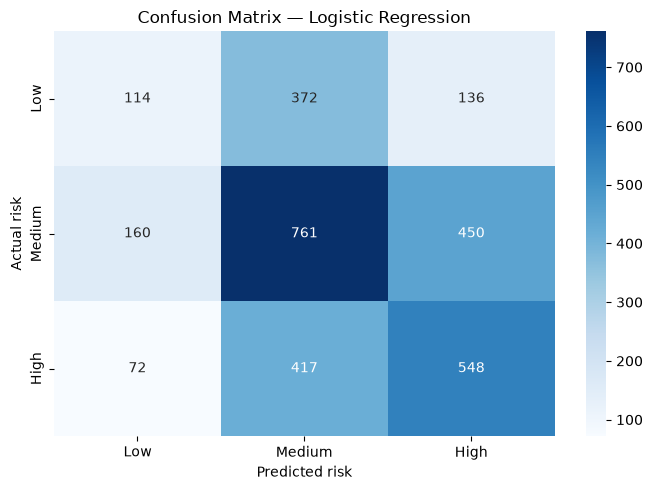

\nPhase 4 completed.
Results saved in: C:\Users\Vipin Soni\OneDrive\Desktop\Cybercrime-Cash-Withdrawal-Forecast\results
Model saved in: C:\Users\Vipin Soni\OneDrive\Desktop\Cybercrime-Cash-Withdrawal-Forecast\models\best_risk_classifier.joblib


In [1]:
"""
Phase 4 — Hyperparameter Optimization
Cybercrime Cash-Withdrawal Location Forecast

Synthetic academic dataset only. Forecast assumes daily aggregates are available
at the end of the observation day. Uses chronological holdout and date-based CV.
"""

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
CLASS_ORDER = ["Low", "Medium", "High"]

# ---------------------------------------------------------------------
# 1. Load data and recreate every engineered feature
# ---------------------------------------------------------------------
df = pd.read_csv(
    Path("../data/raw/synthetic_atm_data.csv"),
    parse_dates=["date"]
)
df = df.sort_values(["date", "zone_id"]).reset_index(drop=True)

df["withdrawals_per_atm"] = (
    df["withdrawal_count"] / df["atm_count"].replace(0, np.nan)
)
df["unusual_activity_ratio"] = (
    df["unusual_activity_count"] /
    df["withdrawal_count"].replace(0, np.nan)
)
df["avg_daily_incidents_30d"] = df["incidents_sum_30d"] / 30
df["withdrawal_amount_per_atm"] = (
    df["total_withdrawal_amount"] / df["atm_count"].replace(0, np.nan)
)

# The generator uses a known 30-day cycle. Date is known at forecast time.
day_index = (df["date"] - pd.Timestamp("2025-01-01")).dt.days
df["season_30d_sin"] = np.sin(2 * np.pi * day_index / 30)
df["season_30d_cos"] = np.cos(2 * np.pi * day_index / 30)
df = df.replace([np.inf, -np.inf], np.nan)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

# ---------------------------------------------------------------------
# 2. Predictors and target
# Exclude current-day incident outcome and both target columns.
# ---------------------------------------------------------------------
FEATURES = [
    "zone_id", "latitude", "longitude", "day_of_week", "month",
    "is_weekend", "atm_count", "withdrawal_count",
    "avg_withdrawal_amount", "total_withdrawal_amount",
    "unusual_activity_count", "withdrawals_sum_7d",
    "unusual_activity_sum_7d", "incidents_sum_7d",
    "withdrawals_sum_30d", "unusual_activity_sum_30d",
    "incidents_sum_30d", "withdrawals_per_atm",
    "unusual_activity_ratio", "avg_daily_incidents_30d",
    "withdrawal_amount_per_atm", "season_30d_sin", "season_30d_cos"
]
TARGET = "target_risk"

missing = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

X = df[FEATURES].copy()
y = df[TARGET].astype(str).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of predictors:", len(FEATURES))
print(y.value_counts().reindex(CLASS_ORDER))

# ---------------------------------------------------------------------
# 3. Chronological holdout with seven-day embargo
# ---------------------------------------------------------------------
unique_dates = np.sort(df["date"].unique())
split_index = int(len(unique_dates) * 0.80)
test_start = pd.Timestamp(unique_dates[split_index])
train_end = test_start - pd.Timedelta(days=7)

train_mask = df["date"] < train_end
test_mask = df["date"] >= test_start

X_train = X.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)
train_row_dates = df.loc[train_mask, "date"].reset_index(drop=True)
test_row_dates = df.loc[test_mask, "date"].reset_index(drop=True)

print("\\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_row_dates.min().date(), "to",
      train_row_dates.max().date())
print("Testing period:", test_row_dates.min().date(), "to",
      test_row_dates.max().date())
print("\\nTraining classes:\\n", y_train.value_counts().reindex(CLASS_ORDER))
print("\\nTesting classes:\\n", y_test.value_counts().reindex(CLASS_ORDER))

if set(y_train.unique()) != set(CLASS_ORDER):
    raise ValueError("Training split does not contain all three classes.")
if set(y_test.unique()) != set(CLASS_ORDER):
    raise ValueError("Test split does not contain all three classes.")

# ---------------------------------------------------------------------
# 4. Expanding-window CV over unique dates, with seven-day gap
# ---------------------------------------------------------------------
N_SPLITS = 5
VALIDATION_DAYS = 30
unique_train_dates = np.sort(train_row_dates.unique())

if len(unique_train_dates) <= N_SPLITS * VALIDATION_DAYS + 7:
    raise ValueError("Not enough dates for the selected time-series CV setup.")

date_splitter = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=VALIDATION_DAYS,
    gap=7
)

cv_splits = []
for train_date_idx, valid_date_idx in date_splitter.split(unique_train_dates):
    fold_train_dates = unique_train_dates[train_date_idx]
    fold_valid_dates = unique_train_dates[valid_date_idx]
    fold_train_idx = np.flatnonzero(
        train_row_dates.isin(fold_train_dates).to_numpy()
    )
    fold_valid_idx = np.flatnonzero(
        train_row_dates.isin(fold_valid_dates).to_numpy()
    )
    cv_splits.append((fold_train_idx, fold_valid_idx))

for i, (tr, va) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: {len(tr)} train rows, {len(va)} validation rows; "
        f"validation {train_row_dates.iloc[va].min().date()} to "
        f"{train_row_dates.iloc[va].max().date()}"
    )

# ---------------------------------------------------------------------
# 5. Preprocessing pipelines
# Fit imputers/scaler/encoder inside each CV training fold.
# ---------------------------------------------------------------------
NUMERIC_FEATURES = [c for c in FEATURES if c != "zone_id"]
CATEGORICAL_FEATURES = ["zone_id"]

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
    ])

def make_pipeline(classifier):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", classifier)
    ])

# ---------------------------------------------------------------------
# 6. Logistic Regression — GridSearchCV
# ---------------------------------------------------------------------
logistic_search = GridSearchCV(
    estimator=make_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ),
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    refit=True,
    verbose=1
)
logistic_search.fit(X_train, y_train)
print("\\nLogistic Regression best CV macro F1:",
      round(logistic_search.best_score_, 4))
print("Parameters:", logistic_search.best_params_)

# ---------------------------------------------------------------------
# 7. SVM — GridSearchCV
# probability=True enables multiclass ROC-AUC evaluation later.
# ---------------------------------------------------------------------
svm_search = GridSearchCV(
    estimator=make_pipeline(
        SVC(probability=True, random_state=RANDOM_STATE)
    ),
    param_grid={
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01],
        "classifier__kernel": ["rbf"],
        "classifier__class_weight": [None, "balanced"]
    },
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    refit=True,
    verbose=1
)
svm_search.fit(X_train, y_train)
print("\\nSVM best CV macro F1:", round(svm_search.best_score_, 4))
print("Parameters:", svm_search.best_params_)

# ---------------------------------------------------------------------
# 8. Random Forest — RandomizedSearchCV
# ---------------------------------------------------------------------
rf_search = RandomizedSearchCV(
    estimator=make_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)
    ),
    param_distributions={
        "classifier__n_estimators": [150, 250, 400],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", 0.7],
        "classifier__class_weight": [None, "balanced", "balanced_subsample"]
    },
    n_iter=10,
    scoring="f1_macro",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    verbose=1
)
rf_search.fit(X_train, y_train)
print("\\nRandom Forest best CV macro F1:",
      round(rf_search.best_score_, 4))
print("Parameters:", rf_search.best_params_)

# ---------------------------------------------------------------------
# 9. Compare cross-validation search results
# ---------------------------------------------------------------------
searches = {
    "Logistic Regression": logistic_search,
    "SVM": svm_search,
    "Random Forest": rf_search
}
cv_comparison = pd.DataFrame([
    {
        "Model": name,
        "Best CV Macro F1": search.best_score_,
        "Best Parameters": search.best_params_
    }
    for name, search in searches.items()
]).sort_values("Best CV Macro F1", ascending=False).reset_index(drop=True)

display(cv_comparison)

# ---------------------------------------------------------------------
# 10. Final evaluation on untouched chronological test set
# ---------------------------------------------------------------------
test_results = []
test_predictions = {}

for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    test_predictions[name] = pred

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(
            y_test, pred, labels=CLASS_ORDER,
            average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, pred, labels=CLASS_ORDER,
            average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_test, pred, labels=CLASS_ORDER,
            average="macro", zero_division=0
        ),
        "F1 (weighted)": f1_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "ROC-AUC (OVR macro)": roc_auc_score(
            y_test, proba, labels=model.classes_,
            multi_class="ovr", average="macro"
        )
    })

test_results_df = pd.DataFrame(test_results).sort_values(
    "F1 (macro)", ascending=False
).reset_index(drop=True)
display(test_results_df.round(4))

# ---------------------------------------------------------------------
# 11. Majority-class baseline
# ---------------------------------------------------------------------
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_result = pd.DataFrame([{
    "Model": "Majority-class baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, baseline_pred),
    "Precision (macro)": precision_score(
        y_test, baseline_pred, labels=CLASS_ORDER,
        average="macro", zero_division=0
    ),
    "Recall (macro)": recall_score(
        y_test, baseline_pred, labels=CLASS_ORDER,
        average="macro", zero_division=0
    ),
    "F1 (macro)": f1_score(
        y_test, baseline_pred, labels=CLASS_ORDER,
        average="macro", zero_division=0
    ),
    "F1 (weighted)": f1_score(
        y_test, baseline_pred, average="weighted", zero_division=0
    ),
    "ROC-AUC (OVR macro)": np.nan
}])

all_test_results = pd.concat(
    [test_results_df, baseline_result], ignore_index=True
)
display(all_test_results.round(4))


# ---------------------------------------------------------
# 12. Best tuned model: detailed report and confusion matrix
# ---------------------------------------------------------

# Select the best model using cross-validation Macro F1
best_model_name = cv_comparison.iloc[0]["Model"]

# Retrieve the trained best model
best_model = searches[best_model_name].best_estimator_

# Retrieve its test predictions
best_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=CLASS_ORDER,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=CLASS_ORDER
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted risk")
plt.ylabel("Actual risk")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# 13. Save outputs and selected model
# ---------------------------------------------------------------------
RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

cv_comparison.to_csv(RESULTS_DIR / "phase4_cv_comparison.csv", index=False)
all_test_results.to_csv(RESULTS_DIR / "phase4_test_metrics.csv", index=False)

report = classification_report(
    y_test, best_predictions, labels=CLASS_ORDER,
    output_dict=True, zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "phase4_best_model_classification_report.csv"
)

pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in CLASS_ORDER],
    columns=[f"Predicted_{c}" for c in CLASS_ORDER]
).to_csv(RESULTS_DIR / "phase4_best_model_confusion_matrix.csv")

with open(RESULTS_DIR / "phase4_best_parameters.json", "w", encoding="utf-8") as f:
    json.dump(
        {name: search.best_params_ for name, search in searches.items()},
        f, indent=4, default=str
    )

model_bundle = {
    "model": best_model,
    "features": FEATURES,
    "target": TARGET,
    "class_order": CLASS_ORDER,
    "forecast_horizon_days": 7,
    "forecast_timing": (
        "End of observation day; current-day aggregates assumed available"
    ),
    "dataset_type": "Synthetic academic data"
}
joblib.dump(model_bundle, MODELS_DIR / "best_risk_classifier.joblib")

print("\\nPhase 4 completed.")
print("Results saved in:", RESULTS_DIR.resolve())
print("Model saved in:", (MODELS_DIR / "best_risk_classifier.joblib").resolve())

# Academic reporting reminder:
# These results describe only the synthetic dataset. They do not establish
# real-world predictive performance or identify actual crime locations.
